<a href="https://colab.research.google.com/github/maybsalty/Deep-Learning-CIFAR100-project/blob/main/4930_model1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
ANIMALS_PEOPLE_INDICES = [
 1, 2, 3, 4, 6, 7,
 11, 14, 15, 18, 19,
 21, 24, 26, 27, 29,
 30, 31, 32, 34, 35, 36, 38,
 42, 43, 44, 45, 46,
 50, 55, 57,
 63, 64, 65, 66, 67,
 72, 73, 74, 75, 77, 78, 79,
 80,
 91, 93, 95, 97, 98, 99,
]
import numpy as np
from tensorflow import keras
from tensorflow.keras.datasets import cifar100
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Input, Add, Dense, Activation, ZeroPadding2D, BatchNormalization, Flatten, Conv2D, AveragePooling2D, MaxPooling2D, GlobalMaxPooling2D
from tensorflow.keras import regularizers, layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.python.keras.initializers import glorot_uniform
from tensorflow.python.keras.models import Model, load_model
import os
from keras.applications.resnet50 import ResNet50
def select_animals_people(y):
    """Returns a boolean mask for selecting animals/people in y"""
    return np.isin(np.ravel(y), ANIMALS_PEOPLE_INDICES)
def compress_animals_people_indices(y):
    """Maps indices in y to range 0 to 49"""
    out = np.zeros(100)
    for i, index in enumerate(ANIMALS_PEOPLE_INDICES):
      out[index] = i
    return out[y]
def load_cifar100_animals_people():
 """Loads a subset of CIFAR100 of animals and people"""
 (X_train, y_train), (X_test, y_test) = cifar100.load_data()
 mask_train = select_animals_people(y_train)
 X_train, y_train = X_train[mask_train], y_train[mask_train]
 mask_test = select_animals_people(y_test)
 X_test, y_test = X_test[mask_test], y_test[mask_test]
 y_train = compress_animals_people_indices(y_train)
 y_test = compress_animals_people_indices(y_test)
 return X_train, y_train, X_test, y_test

In [2]:
final_values = {}
def history_final_values(history):
    return {k: round(v[-1], 4) for k, v in history.history.items()}
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history):
    df = pd.DataFrame(history.history)
    df.index = df.index + 1
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    df.plot(y=["loss", "val_loss"], grid=True, ax=axs[0])
    df.plot(y=["acc", "val_acc"], grid=True, ax=axs[1])
    plt.tight_layout()

In [3]:
X_train, y_train, X_test, y_test = load_cifar100_animals_people()

early_stop3 = EarlyStopping(
    monitor='val_loss',
    patience=3,               # Stop if val_loss doesn't improve for 3 epochs
    restore_best_weights=True)

early_stop5 = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Stop if val_loss doesn't improve for 10 epochs
    restore_best_weights=True,
    )

l2 = regularizers.l2(1e-3)

checkpointresnet50 = ModelCheckpoint('best_resnet50_model.keras',monitor='val_accuracy',save_best_only=True,mode='max',verbose=1)
checkpointefficentnetb0 = ModelCheckpoint('best_efficentnetb0_model.keras',monitor='val_accuracy',save_best_only=True,mode='max',verbose=1)

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1604s 9us/step


Bottleneck Attribution Module

In [4]:
import tensorflow as tf
from tensorflow.keras import layers

class ChannelGate(layers.Layer):
    def __init__(self, ratio=16, **kwargs):
        super(ChannelGate, self).__init__(**kwargs)
        self.ratio = ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        reduced_channels = max(1, channels // self.ratio)

        self.avg_pool = layers.GlobalAveragePooling2D()
        self.fc1 = layers.Dense(reduced_channels, use_bias=True)
        self.bn1 = layers.BatchNormalization()
        self.relu = layers.Activation('relu')
        self.fc2 = layers.Dense(channels, use_bias=True)

    def call(self, inputs):
        x = self.avg_pool(inputs)
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        out = self.fc2(x)
        # Reshape to match spatial shape: (Batch, 1, 1, Channels)
        return layers.Reshape((1, 1, inputs.shape[-1]))(out)

class SpatialGate(layers.Layer):
    def __init__(self, ratio=16, dilation_val=4, **kwargs):
        super(SpatialGate, self).__init__(**kwargs)
        self.ratio = ratio
        self.dilation_val = dilation_val

    def build(self, input_shape):
        channels = input_shape[-1]
        reduced_channels = max(1, channels // self.ratio)

        # 1x1 Reduction Conv -> BN -> ReLU
        self.conv_reduce = layers.Conv2D(reduced_channels, kernel_size=1, use_bias=False)
        self.bn_reduce = layers.BatchNormalization()
        self.relu0 = layers.Activation('relu')

        # Dilated 3x3 Convolutions
        self.conv_di1 = layers.Conv2D(
            reduced_channels, kernel_size=3, padding='same',
            dilation_rate=self.dilation_val, use_bias=False
        )
        self.bn_di1 = layers.BatchNormalization()
        self.relu1 = layers.Activation('relu')

        self.conv_di2 = layers.Conv2D(
            reduced_channels, kernel_size=3, padding='same',
            dilation_rate=self.dilation_val, use_bias=False
        )
        self.bn_di2 = layers.BatchNormalization()
        self.relu2 = layers.Activation('relu')

        # Final 1x1 Conv projecting to 1 spatial channel
        self.conv_final = layers.Conv2D(1, kernel_size=1, use_bias=False)

    def call(self, inputs):
        x = self.conv_reduce(inputs)
        x = self.bn_reduce(x)
        x = self.relu0(x)

        x = self.conv_di1(x)
        x = self.bn_di1(x)
        x = self.relu1(x)

        x = self.conv_di2(x)
        x = self.bn_di2(x)
        x = self.relu2(x)

        return self.conv_final(x)

def BAM(inputs, ratio=16, dilation_val=4):
    """
    BAM (Bottleneck Attention Module)
    Calculates channel and spatial gates in parallel, adds them together,
    applies scaling function (1 + Sigmoid), and multiplies with the input.
    """
    channel_out = ChannelGate(ratio=ratio)(inputs)
    spatial_out = SpatialGate(ratio=ratio, dilation_val=dilation_val)(inputs)

    # Combine parallel branches: M(F) = 1 + Sigmoid( ChannelGate(F) + SpatialGate(F) )
    att_logits = layers.Add()([channel_out, spatial_out])
    att_sig = layers.Activation('sigmoid')(att_logits)
    att_scaled = layers.Lambda(lambda x: 1.0 + x)(att_sig)

    return layers.Multiply()([inputs, att_scaled])

Convolutional Block Attention Module

In [5]:
class ChannelAttention(layers.Layer):
    def __init__(self, ratio=8, **kwargs):
        super(ChannelAttention, self).__init__(**kwargs)
        self.ratio = ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        self.shared_dense_1 = layers.Dense(channels // self.ratio, activation='relu', use_bias=False)
        self.shared_dense_2 = layers.Dense(channels, use_bias=False)
        self.avg_pool = layers.GlobalAveragePooling2D()
        self.max_pool = layers.GlobalMaxPooling2D()

    def call(self, inputs):
        avg_out = self.avg_pool(inputs)
        max_out = self.max_pool(inputs)

        avg_out = self.shared_dense_1(avg_out)
        avg_out = self.shared_dense_2(avg_out)

        max_out = self.shared_dense_1(max_out)
        max_out = self.shared_dense_2(max_out)

        out = layers.Add()([avg_out, max_out])
        out = layers.Activation('sigmoid')(out)

        # Expand dimensions to match input (Batch, 1, 1, Channels)
        out = layers.Reshape((1, 1, inputs.shape[-1]))(out)
        return layers.Multiply()([inputs, out])

class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super(SpatialAttention, self).__init__(**kwargs)
        self.conv = layers.Conv2D(1, kernel_size=kernel_size, padding='same', activation='sigmoid')

    def call(self, inputs):
        avg_out = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_out = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = layers.Concatenate(axis=-1)([avg_out, max_out])
        out = self.conv(concat)
        return layers.Multiply()([inputs, out])

def CBAM(inputs):
    x = ChannelAttention()(inputs)
    x = SpatialAttention()(x)
    return x

Model 1: MobileNetv2

Unique labels: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49.]
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_CIFAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,221,234 (19.92 MB)

 Trainable params: 2,962,738 (11.30 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

Epoch 1/20
1563/1563 - 67s - 43ms/step - acc: 0.2778 - loss: 3.3349 - val_acc: 0.4292 - val_loss: 2.8086
Epoch 2/20
1563/1563 - 32s - 21ms/step - acc: 0.3870 - loss: 2.9033 - val_acc: 0.4674 - val_loss: 2.4601
Epoch 3/20
1563/1563 - 34s - 22ms/step - acc: 0.4358 - loss: 2.6299 - val_acc: 0.4990 - val_loss: 2.1994
Epoch 4/20
1563/1563 - 33s - 21ms/step - acc: 0.4726 - loss: 2.4053 - val_acc: 0.5194 - val_loss: 2.0239
Epoch 5/20
1563/1563 - 33s - 21ms/step - acc: 0.5062 - loss: 2.2110 - val_acc: 0.5294 - val_loss: 1.8853
Epoch 6/20
1563/1563 - 33s - 21ms/step - acc: 0.5314 - loss: 2.0516 - val_acc: 0.5516 - val_loss: 1.7565
Epoch 7/20
1563/1563 - 33s - 21ms/step - acc: 0.5570 - loss: 1.9188 - val_acc: 0.5474 - val_loss: 1.7020
Epoch 8/20
1563/1563 - 33s - 21ms/step - acc: 0.5814 - loss: 1.7937 - val_acc: 0.5580 - val_loss: 1.6384
Epoch 9/20
1563/1563 - 33s - 21ms/step - acc: 0.6043 - loss: 1.6773 - val_acc: 0.5684 - val_loss: 1.5812
Epoch 10/20
1563/1563 - 33s - 21ms/step - acc: 0.6194 -

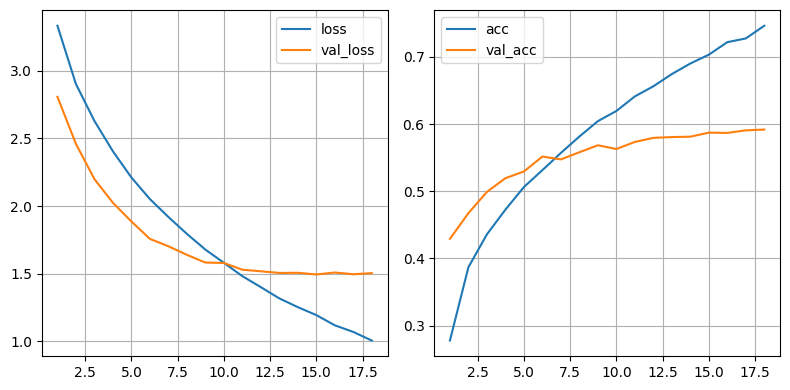

In [6]:
X_train, y_train, X_test, y_test = load_cifar100_animals_people()
print("Unique labels:", np.unique(y_train))
# debugging
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 50)
y_test = to_categorical(y_test, 50)



def create_mobilenetv2_model(input_shape=(32, 32, 3), num_classes=50):
    inputs = layers.Input(input_shape)

    x = layers.Resizing(224,224)(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    base_model = tf.keras.applications.MobileNetV2(include_top=False,
                                                   weights='imagenet',
                                                   input_shape=(224,224,3))
    base_model.trainable = False # Freezing the layers

     # Dense layers
    x = base_model(x, training = False)

    x = layers.Conv2D(256,(3,3),padding="same", activation='softmax')(x)
    x = layers.BatchNormalization()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.6)(x) # Dropout
    outputs = keras.layers.Dense(num_classes,
                                 activation='softmax',
                                 activity_regularizer=l2)(x)
    model = keras.Model(inputs, outputs)

    return models.Model(inputs=inputs,
                        outputs=outputs,
                        name="MobileNetV2_CIFAR")

model = create_mobilenetv2_model(
    input_shape=X_train.shape[1:], num_classes=50)

model.compile(loss="categorical_crossentropy",
                   optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                   metrics=["acc"])
model.summary()
history = model.fit(X_train,
                    y_train,
                    epochs=20,
                    batch_size=16,
                    validation_data=(X_test,y_test),
                    verbose=2,
                    callbacks=[early_stop3]
)

final_values[model.name] = history_final_values(history)
print(final_values[model.name])
plot_history(history)
model.save('best_mobilenetv2_model.h5')

Model 2: ResNet50 with CBAM

Unique labels: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49.]
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_1 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ channel_attention               │ (None, 7, 7, 2048)     │     1,048,576 │
│ (ChannelAttention)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_attention               │ (None, 7, 7, 2048)     │            99 │
│ (SpatialAttention)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 2048)     │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │       102,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,747,029 (94.40 MB)

 Trainable params: 24,689,813 (94.18 MB)

 Non-trainable params: 57,216 (223.50 KB)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/model_checkpoint.py:276: UserWarning: Can save best model only with val_accuracy available.
  if self._should_save_model(epoch, batch, logs, filepath):



Epoch 1: finished saving model to best_resnet50_model.keras
391/391 - 379s - 970ms/step - acc: 0.0429 - loss: 4.0305 - val_acc: 0.0192 - val_loss: 4.2953
Epoch 2/30

Epoch 2: finished saving model to best_resnet50_model.keras
391/391 - 243s - 622ms/step - acc: 0.1662 - loss: 3.3516 - val_acc: 0.0914 - val_loss: 3.6365
Epoch 3/30

Epoch 3: finished saving model to best_resnet50_model.keras
391/391 - 243s - 622ms/step - acc: 0.3254 - loss: 2.6746 - val_acc: 0.4362 - val_loss: 2.3291
Epoch 4/30

Epoch 4: finished saving model to best_resnet50_model.keras
391/391 - 243s - 622ms/step - acc: 0.4402 - loss: 2.1654 - val_acc: 0.5372 - val_loss: 1.8524
Epoch 5/30

Epoch 5: finished saving model to best_resnet50_model.keras
391/391 - 243s - 622ms/step - acc: 0.5318 - loss: 1.7984 - val_acc: 0.5832 - val_loss: 1.6130
Epoch 6/30

Epoch 6: finished saving model to best_resnet50_model.keras
391/391 - 242s - 619ms/step - acc: 0.6014 - loss: 1.5049 - val_acc: 0.6168 - val_loss: 1.4454
Epoch 7/30

Epo

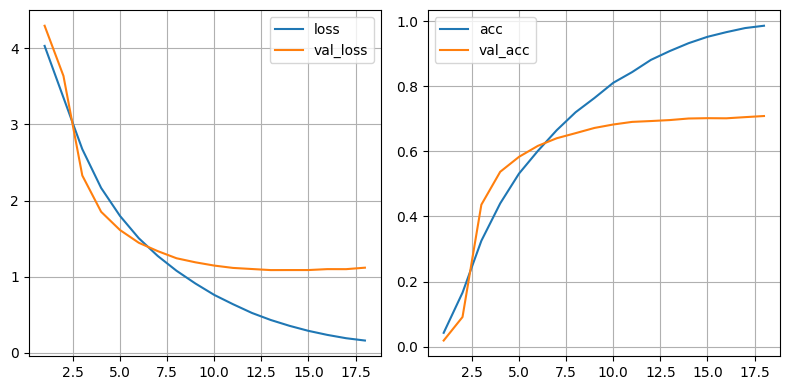

In [7]:
X_train, y_train, X_test, y_test = load_cifar100_animals_people()
print("Unique labels:", np.unique(y_train))
# debugging
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 50)
y_test = to_categorical(y_test, 50)
def create_resnet50_cbam_model(input_shape=(32, 32, 3), num_classes=50):
    inputs = layers.Input(input_shape)

    x = layers.Resizing(224,224)(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    base_model = tf.keras.applications.ResNet50(include_top=False,
                                                   weights='imagenet',
                                                   input_shape=(224,224,3))
    base_model.trainable = True # not freezing the layers

     # Dense layers
    x = base_model(x, training = False)
    x = CBAM(x)

    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.7)(x) # Dropout
    outputs = keras.layers.Dense(num_classes,
                                 activation='softmax',
                                 activity_regularizer=l2
                                 )(x)
    model = keras.Model(inputs, outputs)

    return models.Model(inputs=inputs,
                        outputs=outputs,
                        name="ResNet50")

model = create_resnet50_cbam_model(
    input_shape=X_train.shape[1:], num_classes=50)


# model compiling
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), loss='categorical_crossentropy', metrics=['acc'])
model.summary()
history = model.fit(X_train,
                    y_train,
                    epochs=30,
                    batch_size=64,
                    validation_data=(X_test,y_test),
                    verbose=2,
                    callbacks=[checkpointresnet50,early_stop5]
)

final_values[model.name] = history_final_values(history)
print(final_values[model.name])
plot_history(history)
model.save('best_resnet50_model.h5')

Model 3: EfficientNetB0 + BAM

Unique labels: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49.]
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing_2          │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Resizing)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ resizing_2[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_gate        │ (None, 1, 1,      │    206,480 │ efficientnetb0[0… │
│ (ChannelGate)       │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_gate        │ (None, 7, 7, 1)   │    218,640 │ efficientnetb0[0… │
│ (SpatialGate)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 7, 7,      │          0 │ channel_gate[0][… │
│                     │ 1280)             │            │ spatial_gate[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 7, 7,      │          0 │ add_4[0][0]       │
│ (Activation)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 7, 7,      │          0 │ activation_8[0][… │
│                     │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_9          │ (None, 7, 7,      │          0 │ efficientnetb0[0… │
│ (Multiply)          │ 1280)             │            │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7,      │      5,120 │ multiply_9[0][0]  │
│ (BatchNormalizatio… │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 50)        │     64,050 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,543,861 (17.33 MB)

 Trainable params: 4,498,638 (17.16 MB)

 Non-trainable params: 45,223 (176.66 KB)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/model_checkpoint.py:276: UserWarning: Can save best model only with val_accuracy available.
  if self._should_save_model(epoch, batch, logs, filepath):



Epoch 1: finished saving model to best_efficentnetb0_model.keras
782/782 - 290s - 371ms/step - acc: 0.3138 - loss: 2.7031 - val_acc: 0.6630 - val_loss: 1.2755
Epoch 2/30

Epoch 2: finished saving model to best_efficentnetb0_model.keras
782/782 - 103s - 131ms/step - acc: 0.6346 - loss: 1.3042 - val_acc: 0.7564 - val_loss: 0.8294
Epoch 3/30

Epoch 3: finished saving model to best_efficentnetb0_model.keras
782/782 - 101s - 129ms/step - acc: 0.7379 - loss: 0.9160 - val_acc: 0.7904 - val_loss: 0.7108
Epoch 4/30

Epoch 4: finished saving model to best_efficentnetb0_model.keras
782/782 - 101s - 129ms/step - acc: 0.7947 - loss: 0.7095 - val_acc: 0.8098 - val_loss: 0.6595
Epoch 5/30

Epoch 5: finished saving model to best_efficentnetb0_model.keras
782/782 - 101s - 129ms/step - acc: 0.8407 - loss: 0.5549 - val_acc: 0.8162 - val_loss: 0.6431
Epoch 6/30

Epoch 6: finished saving model to best_efficentnetb0_model.keras
782/782 - 101s - 129ms/step - acc: 0.8718 - loss: 0.4479 - val_acc: 0.8182 - va

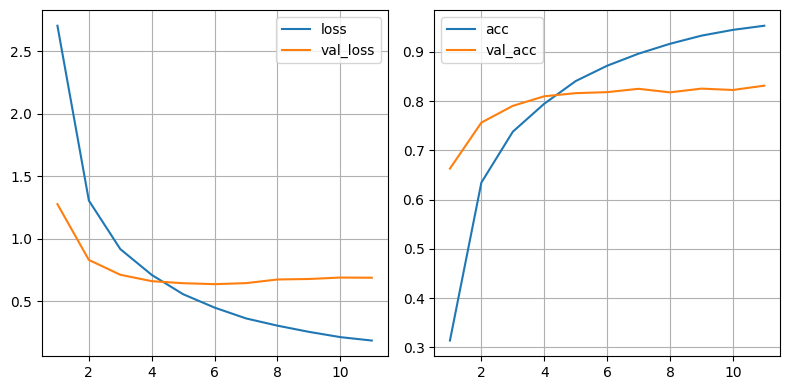

In [8]:
X_train, y_train, X_test, y_test = load_cifar100_animals_people()
print("Unique labels:", np.unique(y_train))
# debugging
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 50)
y_test = to_categorical(y_test, 50)
def create_efficientnetb0_bam_model(input_shape=(32, 32, 3), num_classes=50):
    inputs = layers.Input(input_shape)

    x = layers.Resizing(224,224)(inputs)
    base_model = tf.keras.applications.EfficientNetB0(include_top=False,
                                                   weights='imagenet',
                                                   input_shape=(224,224,3))
    base_model.trainable = True # not freezing the layers

     # Dense layers
    x = base_model(x, training = False)
    x = BAM(x, ratio=16, dilation_val=4)

    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.7)(x) # Dropout
    outputs = keras.layers.Dense(num_classes,
                                 activation='softmax',
                                 activity_regularizer=l2
                                 )(x)
    model = keras.Model(inputs, outputs)

    return models.Model(inputs=inputs,
                        outputs=outputs,
                        name="ResNet50")

model = create_efficientnetb0_bam_model(
    input_shape=X_train.shape[1:], num_classes=50)


# model compiling
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['acc'])
model.summary()
history = model.fit(X_train,
                    y_train,
                    epochs=30,
                    batch_size=32,
                    validation_data=(X_test,y_test),
                    verbose=2,
                    callbacks=[checkpointefficentnetb0,early_stop5]
)

final_values[model.name] = history_final_values(history)
print(final_values[model.name])
plot_history(history)
model.save('best_efficientnetb0_model.h5')